In [1]:
from src.data_loader import prepare_futures_data
import pandas as pd
import matplotlib.pyplot as plt
import datetime as dt
import numpy as np
from src.data_loader import prepare_futures_data
from src.bar_builder import build_15min_bars
from src.signal import add_high_volume_breakout_signal

## Strategy Description

This strategy is a **volatility-adjusted short-term momentum strategy** applied to the **IF, IC, IH, and RU futures**.

The strategy works as follows:

1. One-minute market data are aggregated into **15-minute OHLCV bars** within continuous trading sessions.

2. At the end of each 15-minute bar, the strategy calculates the price return over the preceding **60 minutes**.

3. A **short signal** is generated when:

   - the preceding 60-minute return is negative; and
   - its absolute magnitude exceeds the instrument-specific 80th percentile calculated exclusively from the **2015–2018 training period**.

4. The short position is entered at the current bar's closing price and held for **60 minutes**.

5. Overlapping positions in the same instrument are not allowed.

Position size is determined using trailing volatility. Each trade receives a volatility-risk budget equal to **0.5% of the initial capital**. Position sizing is additionally subject to:

- a maximum margin allocation of **20% of initial capital per trade**;
- a maximum total portfolio margin usage of **60%**;
- a maximum of **20 contracts per trade**.

A signal is skipped if even one contract cannot fit within the specified risk or margin constraints.

The backtest includes:

- instrument-specific contract multipliers;
- exchange opening and closing fees;
- close-today fees where applicable;
- one tick of estimated round-trip slippage.

The evaluation periods are:

- **Training:** 2015–2018
- **Validation:** 2019
- **Test:** 2020–2021

### Hypothesis

A sufficiently large negative price movement over the preceding hour tends to continue in the same direction over the following hour.

In [ ]:
df = prepare_futures_data("data/IF9999.CCFX.csv")
df_15_min = build_15min_bars(df)
print(df_15_min.head())

   session_block  group_15min               start                 end    open  \
0              0            0 2010-04-16 09:16:00 2010-04-16 09:30:00  3450.0   
1              0            1 2010-04-16 09:31:00 2010-04-16 09:45:00  3447.0   
2              0            2 2010-04-16 09:46:00 2010-04-16 10:00:00  3448.2   
3              0            3 2010-04-16 10:01:00 2010-04-16 10:15:00  3448.6   
4              0            4 2010-04-16 10:16:00 2010-04-16 10:30:00  3443.0   

     high     low   close  volume         money  open_interest  symbol  \
0  3488.0  3438.0  3446.0  3644.0  3.777728e+09         1114.0  IF1005   
1  3458.2  3443.0  3448.0  3538.0  3.660190e+09         1776.0  IF1005   
2  3449.8  3440.6  3448.6  3402.0  3.517081e+09         2119.0  IF1005   
3  3449.4  3440.2  3443.2  2629.0  2.717742e+09         2316.0  IF1005   
4  3444.4  3429.2  3431.4  3446.0  3.553641e+09         2614.0  IF1005   

   number_of_minutes  
0                 15  
1                 15  

In [3]:
print(df_15_min.shape)
print(df_15_min['start'].min())
print(df_15_min['start'].max())

(47496, 13)
2010-04-16 09:16:00
2021-10-18 14:46:00


In [4]:
first_open_60m = (
    df_15_min
    .groupby("session_block")["open"]
    .shift(3)
)

df_15_min["past_return_60m"] = (
    df_15_min["close"] / first_open_60m - 1
)
print(df_15_min.head())

   session_block  group_15min               start                 end    open  \
0              0            0 2010-04-16 09:16:00 2010-04-16 09:30:00  3450.0   
1              0            1 2010-04-16 09:31:00 2010-04-16 09:45:00  3447.0   
2              0            2 2010-04-16 09:46:00 2010-04-16 10:00:00  3448.2   
3              0            3 2010-04-16 10:01:00 2010-04-16 10:15:00  3448.6   
4              0            4 2010-04-16 10:16:00 2010-04-16 10:30:00  3443.0   

     high     low   close  volume         money  open_interest  symbol  \
0  3488.0  3438.0  3446.0  3644.0  3.777728e+09         1114.0  IF1005   
1  3458.2  3443.0  3448.0  3538.0  3.660190e+09         1776.0  IF1005   
2  3449.8  3440.6  3448.6  3402.0  3.517081e+09         2119.0  IF1005   
3  3449.4  3440.2  3443.2  2629.0  2.717742e+09         2316.0  IF1005   
4  3444.4  3429.2  3431.4  3446.0  3.553641e+09         2614.0  IF1005   

   number_of_minutes  past_return_60m  
0                 15        

In [5]:
next_close_60m = (
    df_15_min
    .groupby("session_block")["close"]
    .shift(-4)
)

df_15_min["future_return_60m"] = (
    next_close_60m / df_15_min["close"] - 1
)
print(df_15_min.head())

   session_block  group_15min               start                 end    open  \
0              0            0 2010-04-16 09:16:00 2010-04-16 09:30:00  3450.0   
1              0            1 2010-04-16 09:31:00 2010-04-16 09:45:00  3447.0   
2              0            2 2010-04-16 09:46:00 2010-04-16 10:00:00  3448.2   
3              0            3 2010-04-16 10:01:00 2010-04-16 10:15:00  3448.6   
4              0            4 2010-04-16 10:16:00 2010-04-16 10:30:00  3443.0   

     high     low   close  volume         money  open_interest  symbol  \
0  3488.0  3438.0  3446.0  3644.0  3.777728e+09         1114.0  IF1005   
1  3458.2  3443.0  3448.0  3538.0  3.660190e+09         1776.0  IF1005   
2  3449.8  3440.6  3448.6  3402.0  3.517081e+09         2119.0  IF1005   
3  3449.4  3440.2  3443.2  2629.0  2.717742e+09         2316.0  IF1005   
4  3444.4  3429.2  3431.4  3446.0  3.553641e+09         2614.0  IF1005   

   number_of_minutes  past_return_60m  future_return_60m  
0        

In [6]:
print(df_15_min.tail())


       session_block  group_15min               start                 end  \
47491           5657            3 2021-10-18 13:46:00 2021-10-18 14:00:00   
47492           5657            4 2021-10-18 14:01:00 2021-10-18 14:15:00   
47493           5657            5 2021-10-18 14:16:00 2021-10-18 14:30:00   
47494           5657            6 2021-10-18 14:31:00 2021-10-18 14:45:00   
47495           5657            7 2021-10-18 14:46:00 2021-10-18 15:00:00   

         open    high     low   close  volume         money  open_interest  \
47491  4842.4  4842.8  4831.2  4834.8  1770.0  2.567918e+09        64498.0   
47492  4834.2  4848.2  4832.0  4847.2  2259.0  3.281533e+09        65377.0   
47493  4847.0  4852.8  4845.4  4845.8  2432.0  3.537805e+09        66560.0   
47494  4845.8  4854.6  4843.2  4846.0  2796.0  4.067918e+09        68229.0   
47495  4846.0  4861.6  4846.0  4860.0  5774.0  8.412290e+09        71872.0   

       symbol  number_of_minutes  past_return_60m  future_return_60m

In [ ]:
start_date_train = dt.datetime(year=2015, month=1, day=1)
end_date_train = dt.datetime(year=2018, month=12, day=31, hour=23, minute=59, second=59)
df_15_min_train = df_15_min[
                (df_15_min['end'] >= start_date_train)
                & (df_15_min['end'] <= end_date_train)
                & (df_15_min['past_return_60m'].notna())
]

threshold_80
print(threshold_80)

0.007315775472200081


In [8]:
df_15_min['signal'] = np.where( df_15_min['past_return_60m'] < -threshold_80, -1, 0)
print(df_15_min['signal'].value_counts())
print(df_15_min.head())

signal
 0    44945
-1     2551
Name: count, dtype: int64
   session_block  group_15min               start                 end    open  \
0              0            0 2010-04-16 09:16:00 2010-04-16 09:30:00  3450.0   
1              0            1 2010-04-16 09:31:00 2010-04-16 09:45:00  3447.0   
2              0            2 2010-04-16 09:46:00 2010-04-16 10:00:00  3448.2   
3              0            3 2010-04-16 10:01:00 2010-04-16 10:15:00  3448.6   
4              0            4 2010-04-16 10:16:00 2010-04-16 10:30:00  3443.0   

     high     low   close  volume         money  open_interest  symbol  \
0  3488.0  3438.0  3446.0  3644.0  3.777728e+09         1114.0  IF1005   
1  3458.2  3443.0  3448.0  3538.0  3.660190e+09         1776.0  IF1005   
2  3449.8  3440.6  3448.6  3402.0  3.517081e+09         2119.0  IF1005   
3  3449.4  3440.2  3443.2  2629.0  2.717742e+09         2316.0  IF1005   
4  3444.4  3429.2  3431.4  3446.0  3.553641e+09         2614.0  IF1005   

   number_o

In [9]:
start_date_train = dt.datetime(year=2015, month=1, day=1)
end_date_train = dt.datetime(year=2018, month=12, day=31, hour=23, minute=59, second=59)
df_15_min_train = df_15_min[
                (df_15_min['end'] >= start_date_train)
                & (df_15_min['end'] <= end_date_train)
                & (df_15_min['future_return_60m'].notna())
                & (df_15_min['signal'] == -1) 
]
print(df_15_min_train.shape)

(245, 16)


In [10]:
start_date_validation = dt.datetime(year=2019, month=1, day=1)
end_date_validation = dt.datetime(year=2019, month=12, day=31, hour=23, minute=59, second=59)
df_15_min_validation = df_15_min[
                (df_15_min['end'] >= start_date_validation)
                & (df_15_min['end'] <= end_date_validation)
                & (df_15_min['future_return_60m'].notna())
                & (df_15_min['signal'] == -1) 
]
print(df_15_min_validation.shape)

(22, 16)


In [11]:
start_date_test = dt.datetime(year=2020, month=1, day=1)
end_date_test = dt.datetime(year=2021, month=12, day=31, hour=23, minute=59, second=59)
df_15_min_test = df_15_min[
                (df_15_min['end'] >= start_date_test)
                & (df_15_min['end'] <= end_date_test)
                & (df_15_min['future_return_60m'].notna())
                & (df_15_min['signal'] == -1) 
]
print(df_15_min_test.shape)

(85, 16)


In [12]:
def remove_overlapping_trades(signals_df, holding_minutes=60):
    selected_indices = []

    for session_block, block in signals_df.groupby(
        "session_block",
        sort=False,
    ):
        block = block.sort_values("end")
        next_allowed_entry = None

        for index, row in block.iterrows():
            entry_time = row["end"]

            if (
                next_allowed_entry is None
                or entry_time >= next_allowed_entry
            ):
                selected_indices.append(index)
                next_allowed_entry = (
                    entry_time
                    + pd.Timedelta(minutes=holding_minutes)
                )

    return (
        signals_df
        .loc[selected_indices]
        .sort_values("end")
        .copy()
    )

train_trades = remove_overlapping_trades(df_15_min_train)
validation_trades = remove_overlapping_trades(df_15_min_validation)
test_trades = remove_overlapping_trades(df_15_min_test)

print("Train:", len(train_trades))
print("Validation:", len(validation_trades))
print("Test:", len(test_trades))

Train: 197
Validation: 22
Test: 85


In [13]:
for trades in [
    train_trades,
    validation_trades,
    test_trades]:
    
    trades["gross_payoff"] = (
        trades["signal"]
        * trades["future_return_60m"]
    )

In [14]:
def calculate_gross_statistics(trades):
    payoff = trades["gross_payoff"]

    return pd.Series({
        "trades": len(trades),
        "mean_payoff_bps": payoff.mean() * 10_000,
        "median_payoff_bps": payoff.median() * 10_000,
        "win_rate_pct": (payoff > 0).mean() * 100,
        "standard_error_bps": (
            payoff.std() / np.sqrt(len(payoff)) * 10_000
        ),
        "t_statistic": (
            payoff.mean()
            / (payoff.std() / np.sqrt(len(payoff)))
        ),
    })

gross_summary = pd.DataFrame({
    "train": calculate_gross_statistics(train_trades),
    "validation": calculate_gross_statistics(validation_trades),
    "test": calculate_gross_statistics(test_trades),
}).T

print(gross_summary)

            trades  mean_payoff_bps  median_payoff_bps  win_rate_pct  \
train        197.0        32.223361          18.719581     59.390863   
validation    22.0         5.809347          -6.552747     36.363636   
test          85.0        18.077827           9.838646     57.647059   

            standard_error_bps  t_statistic  
train                 9.296461     3.466196  
validation           13.359505     0.434848  
test                  7.423448     2.435233  


In [15]:
df_15_min["future_close_60m"] = (
    df_15_min
    .groupby("session_block")["close"]
    .shift(-4)
)

contract_multiplier = 300

open_fee_rate = 0.23 / 10_000
close_fee_rate = 3.45 / 10_000

tick_size = 0.2
slippage_ticks = 1

In [16]:
def add_if_trade_costs(trades):
    trades = trades.copy()

    trades["entry_price"] = trades["close"]

    trades["exit_price"] = (
        trades["entry_price"]
        * (1 + trades["future_return_60m"])
    )

    contract_multiplier = 300
    open_fee_rate = 0.23 / 10_000
    close_fee_rate = 3.45 / 10_000

    tick_size = 0.2
    slippage_ticks = 1

    trades["gross_pnl_cny"] = (
        (trades["entry_price"] - trades["exit_price"])
        * contract_multiplier
    )

    trades["entry_fee_cny"] = (
        trades["entry_price"]
        * contract_multiplier
        * open_fee_rate
    )

    trades["exit_fee_cny"] = (
        trades["exit_price"]
        * contract_multiplier
        * close_fee_rate
    )

    trades["slippage_cny"] = (
        tick_size
        * contract_multiplier
        * slippage_ticks
    )

    trades["total_cost_cny"] = (
        trades["entry_fee_cny"]
        + trades["exit_fee_cny"]
        + trades["slippage_cny"]
    )

    trades["net_pnl_cny"] = (
        trades["gross_pnl_cny"]
        - trades["total_cost_cny"]
    )

    trades["net_payoff"] = (
        trades["net_pnl_cny"]
        / (trades["entry_price"] * contract_multiplier)
    )

    return trades

train_trades = add_if_trade_costs(train_trades)
validation_trades = add_if_trade_costs(validation_trades)
test_trades = add_if_trade_costs(test_trades)

In [17]:
def calculate_net_statistics(trades, contract_multiplier):
    payoff = trades["net_payoff"]

    standard_error = (
        payoff.std()
        / np.sqrt(len(payoff))
    )

    nominal = (
        trades["entry_price"]
        * contract_multiplier
    )

    return pd.Series({
        "trades": len(trades),
        "mean_net_payoff_bps": payoff.mean() * 10_000,
        "median_net_payoff_bps": payoff.median() * 10_000,
        "win_rate_pct": (payoff > 0).mean() * 100,
        "mean_cost_cny": trades["total_cost_cny"].mean(),
        "mean_cost_bps": (
            trades["total_cost_cny"] / nominal
        ).mean() * 10_000,
        "total_net_pnl_cny": trades["net_pnl_cny"].sum(),
        "t_statistic": payoff.mean() / standard_error,
    })


net_summary = pd.DataFrame({
    "train": calculate_net_statistics(
        train_trades,
        contract_multiplier=300,
    ),
    "validation": calculate_net_statistics(
        validation_trades,
        contract_multiplier=300,
    ),
    "test": calculate_net_statistics(
        test_trades,
        contract_multiplier=300,
    ),
}).T

print(net_summary)

print(net_summary)

            trades  mean_net_payoff_bps  median_net_payoff_bps  win_rate_pct  \
train        197.0            27.993934              14.511194     57.868020   
validation    22.0             1.588429             -10.798677     31.818182   
test          85.0            13.971619               5.768495     52.941176   

            mean_cost_cny  mean_cost_bps  total_net_pnl_cny  t_statistic  
train          460.827802       4.229427       618956.92302     3.010157  
validation     468.068133       4.220918         7582.50108     0.118833  
test           577.550524       4.106208       168828.20544     1.881444  
            trades  mean_net_payoff_bps  median_net_payoff_bps  win_rate_pct  \
train        197.0            27.993934              14.511194     57.868020   
validation    22.0             1.588429             -10.798677     31.818182   
test          85.0            13.971619               5.768495     52.941176   

            mean_cost_cny  mean_cost_bps  total_net_pnl_cn

In [18]:
all_trades = pd.concat(
    [
        train_trades.assign(period="train"),
        validation_trades.assign(period="validation"),
        test_trades.assign(period="test"),
    ],
    ignore_index=True,
)

all_trades["year"] = all_trades["end"].dt.year

yearly_if_summary = (
    all_trades
    .groupby(["year", "period"])
    .agg(
        trades=("net_payoff", "size"),
        mean_net_payoff=("net_payoff", "mean"),
        median_net_payoff=("net_payoff", "median"),
        win_rate=("net_payoff", lambda x: (x > 0).mean()),
        total_net_pnl_cny=("net_pnl_cny", "sum"),
    )
)

yearly_if_summary["mean_net_payoff_bps"] = (
    yearly_if_summary["mean_net_payoff"] * 10_000
)

yearly_if_summary["median_net_payoff_bps"] = (
    yearly_if_summary["median_net_payoff"] * 10_000
)

yearly_if_summary["win_rate_pct"] = (
    yearly_if_summary["win_rate"] * 100
)

print(
    yearly_if_summary[
        [
            "trades",
            "mean_net_payoff_bps",
            "median_net_payoff_bps",
            "win_rate_pct",
            "total_net_pnl_cny",
        ]
    ]
)

                 trades  mean_net_payoff_bps  median_net_payoff_bps  \
year period                                                           
2015 train          110            35.921322              17.074194   
2016 train           28            28.868971               2.184112   
2017 train           11           -10.465180               1.013353   
2018 train           48            18.130109              25.788533   
2019 validation      22             1.588429             -10.798677   
2020 test            44            15.010808               8.904974   
2021 test            41            12.856393              -2.230100   

                 win_rate_pct  total_net_pnl_cny  
year period                                       
2015 train          54.545455       469445.98224  
2016 train          50.000000        74763.92988  
2017 train          54.545455       -13189.30488  
2018 train          70.833333        87936.31578  
2019 validation     31.818182         7582.50108  
202

In [19]:
ic_minute = prepare_futures_data("data/IC9999.CCFX.csv")
ic_15min = build_15min_bars(ic_minute)

ic_15min["past_return_60m"] = (
    ic_15min["close"]
    / ic_15min.groupby("session_block")["open"].shift(3)
    - 1
)

ic_15min["future_close_60m"] = (
    ic_15min
    .groupby("session_block")["close"]
    .shift(-4)
)

ic_15min["future_return_60m"] = (
    ic_15min["future_close_60m"]
    / ic_15min["close"]
    - 1
)

ic_train_for_threshold = ic_15min.loc[
    (ic_15min["end"] >= start_date_train)
    & (ic_15min["end"] <= end_date_train)
    & ic_15min["past_return_60m"].notna()
].copy()

ic_threshold_80 = (
    ic_train_for_threshold["past_return_60m"]
    .abs()
    .quantile(0.80)
)

ic_15min["signal"] = np.where(
    ic_15min["past_return_60m"] < -ic_threshold_80,
    -1,
    0,
)

print("IC threshold:", ic_threshold_80)
print("IC threshold, %:", ic_threshold_80 * 100)
print(ic_15min["signal"].value_counts())

IC threshold: 0.009253779523322736
IC threshold, %: 0.9253779523322736
signal
 0    24415
-1     1283
Name: count, dtype: int64


In [20]:
ic_train_signals = ic_15min.loc[
    (ic_15min["end"] >= start_date_train)
    & (ic_15min["end"] <= end_date_train)
    & (ic_15min["signal"] == -1)
    & ic_15min["future_return_60m"].notna()
].copy()

ic_validation_signals = ic_15min.loc[
    (ic_15min["end"] >= start_date_validation)
    & (ic_15min["end"] <= end_date_validation)
    & (ic_15min["signal"] == -1)
    & ic_15min["future_return_60m"].notna()
].copy()

ic_test_signals = ic_15min.loc[
    (ic_15min["end"] >= start_date_test)
    & (ic_15min["end"] <= end_date_test)
    & (ic_15min["signal"] == -1)
    & ic_15min["future_return_60m"].notna()
].copy()

ic_train_trades = remove_overlapping_trades(ic_train_signals)
ic_validation_trades = remove_overlapping_trades(ic_validation_signals)
ic_test_trades = remove_overlapping_trades(ic_test_signals)

print("IC train:", len(ic_train_trades))
print("IC validation:", len(ic_validation_trades))
print("IC test:", len(ic_test_trades))

IC train: 180
IC validation: 29
IC test: 56


In [21]:
for trades in [
    ic_train_trades,
    ic_validation_trades,
    ic_test_trades,
]:
    trades["gross_payoff"] = (
        trades["signal"]
        * trades["future_return_60m"]
    )

ic_gross_summary = pd.DataFrame({
    "train": calculate_gross_statistics(ic_train_trades),
    "validation": calculate_gross_statistics(ic_validation_trades),
    "test": calculate_gross_statistics(ic_test_trades),
}).T

print(ic_gross_summary)

            trades  mean_payoff_bps  median_payoff_bps  win_rate_pct  \
train        180.0        38.055611          10.461716     55.000000   
validation    29.0        16.307289           1.179477     51.724138   
test          56.0        15.660193          18.886849     58.928571   

            standard_error_bps  t_statistic  
train                14.925826     2.549649  
validation           14.811586     1.100982  
test                 11.594496     1.350657  


In [22]:
def add_index_futures_trade_costs(
    trades,
    contract_multiplier,
    tick_size=0.2,
    slippage_ticks=1,
    open_fee_rate=0.23 / 10_000,
    close_fee_rate=3.45 / 10_000,
):
    trades = trades.copy()

    trades["contract_multiplier"] = contract_multiplier

    trades["entry_price"] = trades["close"]

    trades["exit_price"] = (
        trades["entry_price"]
        * (1 + trades["future_return_60m"])
    )

    trades["gross_pnl_cny"] = (
        trades["signal"]
        * (trades["exit_price"] - trades["entry_price"])
        * trades["contract_multiplier"]
    )

    trades["entry_fee_cny"] = (
        trades["entry_price"]
        * trades["contract_multiplier"]
        * open_fee_rate
    )

    trades["exit_fee_cny"] = (
        trades["exit_price"]
        * trades["contract_multiplier"]
        * close_fee_rate
    )

    trades["slippage_cny"] = (
        tick_size
        * trades["contract_multiplier"]
        * slippage_ticks
    )

    trades["total_cost_cny"] = (
        trades["entry_fee_cny"]
        + trades["exit_fee_cny"]
        + trades["slippage_cny"]
    )

    trades["net_pnl_cny"] = (
        trades["gross_pnl_cny"]
        - trades["total_cost_cny"]
    )

    trades["net_payoff"] = (
        trades["net_pnl_cny"]
        / (
            trades["entry_price"]
            * trades["contract_multiplier"]
        )
    )

    return trades


ic_train_trades = add_index_futures_trade_costs(
    ic_train_trades,
    contract_multiplier=200,
)

ic_validation_trades = add_index_futures_trade_costs(
    ic_validation_trades,
    contract_multiplier=200,
)

ic_test_trades = add_index_futures_trade_costs(
    ic_test_trades,
    contract_multiplier=200,
)

ic_net_summary = pd.DataFrame({
    "train": calculate_net_statistics(
        ic_train_trades,
        contract_multiplier=200,
    ),
    "validation": calculate_net_statistics(
        ic_validation_trades,
        contract_multiplier=200,
    ),
    "test": calculate_net_statistics(
        ic_test_trades,
        contract_multiplier=200,
    ),
}).T

print(ic_net_summary)

            trades  mean_net_payoff_bps  median_net_payoff_bps  win_rate_pct  \
train        180.0            34.068633               6.479321     52.777778   
validation    29.0            12.231964              -2.893275     44.827586   
test          56.0            11.649589              14.871640     58.928571   

            mean_cost_cny  mean_cost_bps  total_net_pnl_cny  t_statistic  
train          521.616136       3.986978       952989.09552     2.281638  
validation     408.404102       4.075325        45196.28104     0.825372  
test           482.199758       4.010604        89916.81356     1.004330  


In [23]:
def prepare_short_momentum_strategy(path):
    minute_df = prepare_futures_data(path)
    bars = build_15min_bars(minute_df)

    bars["past_return_60m"] = (
        bars["close"]
        / bars.groupby("session_block")["open"].shift(3)
        - 1
    )

    bars["future_close_60m"] = (
        bars
        .groupby("session_block")["close"]
        .shift(-4)
    )

    bars["future_return_60m"] = (
        bars["future_close_60m"]
        / bars["close"]
        - 1
    )

    threshold_data = bars.loc[
        (bars["end"] >= start_date_train)
        & (bars["end"] <= end_date_train)
        & bars["past_return_60m"].notna()
    ]

    threshold_80 = (
        threshold_data["past_return_60m"]
        .abs()
        .quantile(0.80)
    )

    bars["signal"] = np.where(
        bars["past_return_60m"] < -threshold_80,
        -1,
        0,
    )

    def select_period(start_date, end_date):
        signals = bars.loc[
            (bars["end"] >= start_date)
            & (bars["end"] <= end_date)
            & (bars["signal"] == -1)
            & bars["future_return_60m"].notna()
        ].copy()

        return remove_overlapping_trades(signals)

    trades = {
        "train": select_period(
            start_date_train,
            end_date_train,
        ),
        "validation": select_period(
            start_date_validation,
            end_date_validation,
        ),
        "test": select_period(
            start_date_test,
            end_date_test,
        ),
    }

    return bars, threshold_80, trades

In [24]:
ih_15min, ih_threshold_80, ih_trades = (
    prepare_short_momentum_strategy(
        "data/IH9999.CCFX.csv"
    )
)

print("IH threshold:", ih_threshold_80)
print("IH threshold, %:", ih_threshold_80 * 100)

for period, trades in ih_trades.items():
    print(period, len(trades))

IH threshold: 0.006713831937626313
IH threshold, %: 0.6713831937626313
train 211
validation 30
test 103


In [25]:
for period in ih_trades:
    ih_trades[period] = add_index_futures_trade_costs(
        ih_trades[period],
        contract_multiplier=300,
    )

ih_net_summary = pd.DataFrame({
    period: calculate_net_statistics(
        trades,
        contract_multiplier=300,
    )
    for period, trades in ih_trades.items()
}).T

print(ih_net_summary)

            trades  mean_net_payoff_bps  median_net_payoff_bps  win_rate_pct  \
train        211.0            14.147203              11.606029     54.502370   
validation    30.0             0.334800             -10.360088     30.000000   
test         103.0             6.837563               1.281570     51.456311   

            mean_cost_cny  mean_cost_bps  total_net_pnl_cny  t_statistic  
train          345.748869       4.461980       212886.98856     1.668681  
validation     365.245512       4.403963         3202.63464     0.034550  
test           423.932341       4.288308        75974.96892     1.205737  


In [26]:
ru_15min, ru_threshold_80, ru_trades = (
    prepare_short_momentum_strategy(
        "data/RU9999.XSGE.csv"
    )
)

print("RU threshold:", ru_threshold_80)
print("RU threshold, %:", ru_threshold_80 * 100)

for period, trades in ru_trades.items():
    print(period, len(trades))

RU threshold: 0.006980024883846347
RU threshold, %: 0.6980024883846347
train 92
validation 19
test 28


In [27]:
def add_fixed_fee_trade_costs(
    trades,
    contract_multiplier,
    entry_fee_cny,
    exit_fee_cny,
    tick_size,
    slippage_ticks=1,
):
    trades = trades.copy()

    trades["contract_multiplier"] = contract_multiplier
    trades["entry_price"] = trades["close"]

    trades["exit_price"] = (
        trades["entry_price"]
        * (1 + trades["future_return_60m"])
    )

    trades["gross_pnl_cny"] = (
        trades["signal"]
        * (trades["exit_price"] - trades["entry_price"])
        * contract_multiplier
    )

    trades["entry_fee_cny"] = entry_fee_cny
    trades["exit_fee_cny"] = exit_fee_cny

    trades["slippage_cny"] = (
        tick_size
        * contract_multiplier
        * slippage_ticks
    )

    trades["total_cost_cny"] = (
        trades["entry_fee_cny"]
        + trades["exit_fee_cny"]
        + trades["slippage_cny"]
    )

    trades["net_pnl_cny"] = (
        trades["gross_pnl_cny"]
        - trades["total_cost_cny"]
    )

    trades["net_payoff"] = (
        trades["net_pnl_cny"]
        / (trades["entry_price"] * contract_multiplier)
    )

    return trades

In [28]:
for period in ru_trades:
    ru_trades[period] = add_fixed_fee_trade_costs(
        ru_trades[period],
        contract_multiplier=10,
        entry_fee_cny=3,
        exit_fee_cny=0,
        tick_size=5,
        slippage_ticks=1,
    )

In [29]:
ru_net_summary = pd.DataFrame({
    period: calculate_net_statistics(
        trades,
        contract_multiplier=10,
    )
    for period, trades in ru_trades.items()
}).T

print(ru_net_summary)

            trades  mean_net_payoff_bps  median_net_payoff_bps  win_rate_pct  \
train         92.0            14.101053              -3.951332     44.565217   
validation    19.0            22.136366              20.678108     68.421053   
test          28.0             6.364100             -10.229165     39.285714   

            mean_cost_cny  mean_cost_bps  total_net_pnl_cny  t_statistic  
train                53.0       3.963211            17124.0     1.079927  
validation           53.0       4.612371             4743.0     2.427636  
test                 53.0       3.912639             2866.0     0.430959  


In [30]:
strategy_trades = pd.concat(
    [
        train_trades.assign(
            instrument="IF",
            period="train",
        ),
        validation_trades.assign(
            instrument="IF",
            period="validation",
        ),
        test_trades.assign(
            instrument="IF",
            period="test",
        ),

        ic_train_trades.assign(
            instrument="IC",
            period="train",
        ),
        ic_validation_trades.assign(
            instrument="IC",
            period="validation",
        ),
        ic_test_trades.assign(
            instrument="IC",
            period="test",
        ),

        ih_trades["train"].assign(
            instrument="IH",
            period="train",
        ),
        ih_trades["validation"].assign(
            instrument="IH",
            period="validation",
        ),
        ih_trades["test"].assign(
            instrument="IH",
            period="test",
        ),

        ru_trades["train"].assign(
            instrument="RU",
            period="train",
        ),
        ru_trades["validation"].assign(
            instrument="RU",
            period="validation",
        ),
        ru_trades["test"].assign(
            instrument="RU",
            period="test",
        ),
    ],
    ignore_index=True,
)

strategy_trades = strategy_trades.sort_values("end").reset_index(
    drop=True
)

print(strategy_trades.shape)
print(
    strategy_trades
    .groupby(["instrument", "period"])
    .size()
)

(1052, 30)
instrument  period    
IC          test           56
            train         180
            validation     29
IF          test           85
            train         197
            validation     22
IH          test          103
            train         211
            validation     30
RU          test           28
            train          92
            validation     19
dtype: int64


In [31]:
def summarize_trade_groups(df, group_columns):
    summary = (
        df
        .groupby(group_columns)
        .agg(
            trades=("net_payoff", "size"),
            mean_net_payoff=("net_payoff", "mean"),
            median_net_payoff=("net_payoff", "median"),
            std_net_payoff=("net_payoff", "std"),
            win_rate=("net_payoff", lambda x: (x > 0).mean()),
        )
    )

    summary["standard_error"] = (
        summary["std_net_payoff"]
        / np.sqrt(summary["trades"])
    )

    summary["t_statistic"] = (
        summary["mean_net_payoff"]
        / summary["standard_error"]
    )

    summary["mean_net_payoff_bps"] = (
        summary["mean_net_payoff"] * 10_000
    )

    summary["median_net_payoff_bps"] = (
        summary["median_net_payoff"] * 10_000
    )

    summary["win_rate_pct"] = (
        summary["win_rate"] * 100
    )

    return summary[
        [
            "trades",
            "mean_net_payoff_bps",
            "median_net_payoff_bps",
            "win_rate_pct",
            "t_statistic",
        ]
    ]

instrument_period_summary = summarize_trade_groups(
    strategy_trades,
    ["period", "instrument"],
)

print(instrument_period_summary)

                       trades  mean_net_payoff_bps  median_net_payoff_bps  \
period     instrument                                                       
test       IC              56            11.649589              14.871640   
           IF              85            13.971619               5.768495   
           IH             103             6.837563               1.281570   
           RU              28             6.364100             -10.229165   
train      IC             180            34.068633               6.479321   
           IF             197            27.993934              14.511194   
           IH             211            14.147203              11.606029   
           RU              92            14.101053              -3.951332   
validation IC              29            12.231964              -2.893275   
           IF              22             1.588429             -10.798677   
           IH              30             0.334800             -10.360088   

In [32]:
combined_period_summary = summarize_trade_groups(
    strategy_trades,
    ["period"],
)

print(combined_period_summary)

            trades  mean_net_payoff_bps  median_net_payoff_bps  win_rate_pct  \
period                                                                         
test           272            10.008928               3.225873     52.205882   
train          680            23.425758               8.921082     53.676471   
validation     100             8.203074              -4.514195     42.000000   

            t_statistic  
period                   
test           2.370825  
train          4.084714  
validation     1.327548  


In [33]:
strategy_trades["year"] = strategy_trades["end"].dt.year

yearly_combined_summary = summarize_trade_groups(
    strategy_trades,
    ["period", "year"],
)

print(yearly_combined_summary)

                 trades  mean_net_payoff_bps  median_net_payoff_bps  \
period     year                                                       
test       2020     154             8.740535               3.697053   
           2021     118            11.664289               3.213638   
train      2015     350            34.640445              11.893079   
           2016     117            19.926511              -4.263942   
           2017      56           -12.949738             -11.862904   
           2018     157            14.007282              20.509402   
validation 2019     100             8.203074              -4.514195   

                 win_rate_pct  t_statistic  
period     year                             
test       2020     51.948052     1.429899  
           2021     52.542373     2.083311  
train      2015     54.285714     3.459579  
           2016     44.444444     1.800380  
           2017     42.857143    -0.990366  
           2018     63.057325     2.791252  


In [34]:
yearly_instrument_summary = summarize_trade_groups(
    strategy_trades,
    ["period", "year", "instrument"],
)

print(yearly_instrument_summary)

                            trades  mean_net_payoff_bps  \
period     year instrument                                
test       2020 IC              45            13.911211   
                IF              44            15.010808   
                IH              50             4.372604   
                RU              15           -10.604523   
           2021 IC              11             2.397501   
                IF              41            12.856393   
                IH              53             9.162996   
                RU              13            25.943281   
train      2015 IC              94            60.519593   
                IF             110            35.921322   
                IH             115            17.258827   
                RU              31            16.103332   
           2016 IC              38            12.765326   
                IF              28            28.868971   
                IH              23            20.483850 

In [35]:
yearly_payoff_pivot = (
    yearly_instrument_summary[
        "mean_net_payoff_bps"
    ]
    .unstack("instrument")
)

print(yearly_payoff_pivot)

instrument              IC         IF         IH         RU
period     year                                            
test       2020  13.911211  15.010808   4.372604 -10.604523
           2021   2.397501  12.856393   9.162996  25.943281
train      2015  60.519593  35.921322  17.258827  16.103332
           2016  12.765326  28.868971  20.483850  20.244986
           2017 -26.334823 -10.465180  -7.380657 -11.853627
           2018   5.011364  18.130109  10.126786  57.302332
validation 2019  12.231964   1.588429   0.334800  22.136366


In [36]:
yearly_trades_pivot = (
    yearly_instrument_summary["trades"]
    .unstack("instrument")
)

print(yearly_trades_pivot)

instrument       IC   IF   IH  RU
period     year                  
test       2020  45   44   50  15
           2021  11   41   53  13
train      2015  94  110  115  31
           2016  38   28   23  28
           2017   9   11   12  24
           2018  39   48   61   9
validation 2019  29   22   30  19


In [37]:
initial_capital = 3_000_000

strategy_trades["exit_date"] = (
    strategy_trades["end"].dt.normalize()
)

In [38]:
def build_daily_equity(
    trades,
    start_date,
    end_date,
    initial_capital=3_000_000,
):
    daily_pnl = (
        trades
        .groupby("exit_date")["net_pnl_cny"]
        .sum()
    )

    business_days = pd.date_range(
        start=pd.Timestamp(start_date).normalize(),
        end=pd.Timestamp(end_date).normalize(),
        freq="B",
    )

    daily = pd.DataFrame(index=business_days)

    daily["net_pnl_cny"] = (
        daily_pnl
        .reindex(business_days, fill_value=0)
    )

    daily["cumulative_pnl_cny"] = (
        daily["net_pnl_cny"].cumsum()
    )

    daily["equity_cny"] = (
        initial_capital
        + daily["cumulative_pnl_cny"]
    )

    previous_equity = (
        daily["equity_cny"]
        .shift(1)
        .fillna(initial_capital)
    )

    daily["daily_return"] = (
        daily["net_pnl_cny"]
        / previous_equity
    )

    daily["running_max_equity"] = (
        daily["equity_cny"].cummax()
    )

    daily["drawdown"] = (
        daily["equity_cny"]
        / daily["running_max_equity"]
        - 1
    )

    return daily

In [39]:
train_daily = build_daily_equity(
    strategy_trades.loc[
        strategy_trades["period"] == "train"
    ],
    start_date_train,
    end_date_train,
    initial_capital,
)

validation_daily = build_daily_equity(
    strategy_trades.loc[
        strategy_trades["period"] == "validation"
    ],
    start_date_validation,
    end_date_validation,
    initial_capital,
)

test_daily = build_daily_equity(
    strategy_trades.loc[
        strategy_trades["period"] == "test"
    ],
    start_date_test,
    end_date_test,
    initial_capital,
)

In [40]:
def calculate_equity_statistics(daily):
    number_of_days = len(daily)

    total_return = (
        daily["equity_cny"].iloc[-1]
        / daily["equity_cny"].iloc[0]
        - 1
    )

    annualized_return = (
        (1 + daily["daily_return"]).prod()
        ** (252 / number_of_days)
        - 1
    )

    daily_std = daily["daily_return"].std()

    sharpe = (
        np.sqrt(252)
        * daily["daily_return"].mean()
        / daily_std
        if daily_std > 0
        else np.nan
    )

    return pd.Series({
        "start_equity_cny": initial_capital,
        "end_equity_cny": daily["equity_cny"].iloc[-1],
        "total_pnl_cny": daily["net_pnl_cny"].sum(),
        "total_return_pct": total_return * 100,
        "annualized_return_pct": annualized_return * 100,
        "annualized_sharpe": sharpe,
        "max_drawdown_pct": daily["drawdown"].min() * 100,
        "profitable_days_pct": (
            daily["net_pnl_cny"] > 0
        ).mean() * 100,
    })

equity_summary = pd.DataFrame({
    "train": calculate_equity_statistics(train_daily),
    "validation": calculate_equity_statistics(validation_daily),
    "test": calculate_equity_statistics(test_daily),
}).T

print(equity_summary)

            start_equity_cny  end_equity_cny  total_pnl_cny  total_return_pct  \
train              3000000.0    4.801957e+06   1.801957e+06         60.065234   
validation         3000000.0    3.060724e+06   6.072442e+04          2.024147   
test               3000000.0    3.337586e+06   3.375860e+05         11.252866   

            annualized_return_pct  annualized_sharpe  max_drawdown_pct  \
train                   12.036711           1.420515         -4.505212   
validation               1.953672           0.813864         -2.554458   
test                     5.272367           1.234157         -1.954055   

            profitable_days_pct  
train                 15.915628  
validation            11.877395  
test                  14.149140  


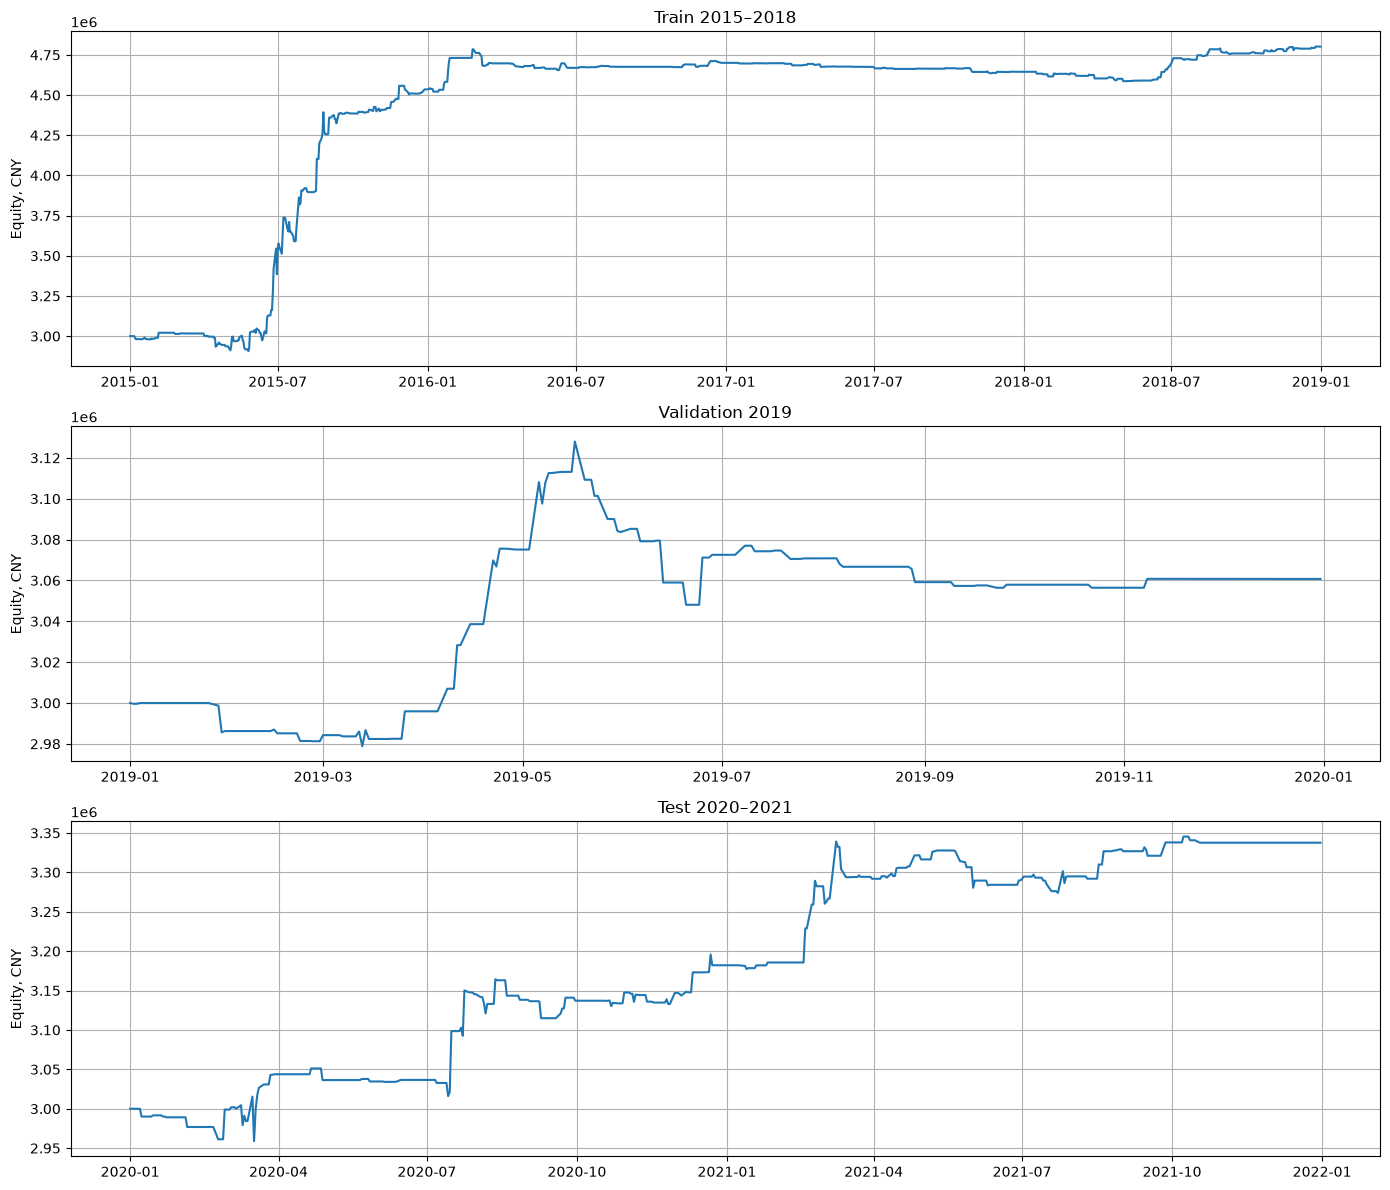

In [41]:
fig, axes = plt.subplots(
    3,
    1,
    figsize=(14, 12),
)

for ax, daily, title in [
    (axes[0], train_daily, "Train 2015–2018"),
    (axes[1], validation_daily, "Validation 2019"),
    (axes[2], test_daily, "Test 2020–2021"),
]:
    ax.plot(
        daily.index,
        daily["equity_cny"],
    )

    ax.set_title(title)
    ax.set_ylabel("Equity, CNY")
    ax.grid(True)

plt.tight_layout()
plt.show()

In [42]:
contract_parameters = pd.DataFrame({
    "instrument": ["IF", "IC", "IH", "RU"],
    "contract_multiplier_check": [300, 200, 300, 10],
    "margin_rate": [0.12, 0.12, 0.12, 0.11],
})
margin_trades = (
    strategy_trades
    .merge(
        contract_parameters,
        on="instrument",
        how="left",
    )
    .copy()
)

margin_trades["entry_time"] = margin_trades["end"]

margin_trades["exit_time"] = (
    margin_trades["entry_time"]
    + pd.Timedelta(minutes=60)
)

margin_trades["notional_cny"] = (
    margin_trades["entry_price"]
    * margin_trades["contract_multiplier_check"]
)

margin_trades["required_margin_cny"] = (
    margin_trades["notional_cny"]
    * margin_trades["margin_rate"]
)

print(
    margin_trades[
        [
            "instrument",
            "entry_time",
            "exit_time",
            "entry_price",
            "notional_cny",
            "required_margin_cny",
        ]
    ].head()
)

  instrument          entry_time           exit_time  entry_price  \
0         IF 2015-01-07 14:00:00 2015-01-07 15:00:00       3622.6   
1         RU 2015-01-07 22:00:00 2015-01-07 23:00:00      13270.0   
2         IF 2015-01-08 10:15:00 2015-01-08 11:15:00       3570.4   
3         IF 2015-01-12 10:15:00 2015-01-12 11:15:00       3540.4   
4         RU 2015-01-12 23:00:00 2015-01-13 00:00:00      13065.0   

   notional_cny  required_margin_cny  
0     1086780.0             130413.6  
1      132700.0              14597.0  
2     1071120.0             128534.4  
3     1062120.0             127454.4  
4      130650.0              14371.5  


In [43]:
entry_events = margin_trades[
    [
        "entry_time",
        "required_margin_cny",
    ]
].copy()

entry_events = entry_events.rename(
    columns={"entry_time": "time"}
)

entry_events["margin_change_cny"] = (
    entry_events["required_margin_cny"]
)

entry_events["position_change"] = 1

exit_events = margin_trades[
    [
        "exit_time",
        "required_margin_cny",
    ]
].copy()

exit_events = exit_events.rename(
    columns={"exit_time": "time"}
)

exit_events["margin_change_cny"] = (
    -exit_events["required_margin_cny"]
)

exit_events["position_change"] = -1

In [44]:
position_events = pd.concat(
    [
        entry_events[
            [
                "time",
                "margin_change_cny",
                "position_change",
            ]
        ],
        exit_events[
            [
                "time",
                "margin_change_cny",
                "position_change",
            ]
        ],
    ],
    ignore_index=True,
)

position_events = (
    position_events
    .groupby("time", as_index=False)
    .agg(
        margin_change_cny=(
            "margin_change_cny",
            "sum",
        ),
        position_change=(
            "position_change",
            "sum",
        ),
    )
    .sort_values("time")
)

position_events["active_margin_cny"] = (
    position_events["margin_change_cny"].cumsum()
)

position_events["active_positions"] = (
    position_events["position_change"].cumsum()
)

In [45]:
margin_summary = pd.Series({
    "maximum_simultaneous_positions": (
        position_events["active_positions"].max()
    ),
    "maximum_required_margin_cny": (
        position_events["active_margin_cny"].max()
    ),
    "maximum_margin_usage_pct": (
        position_events["active_margin_cny"].max()
        / initial_capital
        * 100
    ),
    "median_margin_per_trade_cny": (
        margin_trades["required_margin_cny"].median()
    ),
    "maximum_margin_per_trade_cny": (
        margin_trades["required_margin_cny"].max()
    ),
})

print(margin_summary)

maximum_simultaneous_positions         3.00000
maximum_required_margin_cny       559639.20000
maximum_margin_usage_pct              18.65464
median_margin_per_trade_cny       119736.00000
maximum_margin_per_trade_cny      263059.20000
dtype: float64


In [46]:
def evaluate_contract_scale(
    trades,
    start_date,
    end_date,
    contracts,
    initial_capital=3_000_000,
):
    scaled_trades = trades.copy()

    scaled_trades["net_pnl_cny"] = (
        scaled_trades["net_pnl_cny"]
        * contracts
    )

    daily = build_daily_equity(
        scaled_trades,
        start_date,
        end_date,
        initial_capital,
    )

    statistics = calculate_equity_statistics(daily)

    statistics["contracts_per_signal"] = contracts
    statistics["maximum_margin_usage_pct"] = (
        margin_summary["maximum_margin_usage_pct"]
        * contracts
    )

    return statistics

In [47]:
def evaluate_contract_scale(
    trades,
    start_date,
    end_date,
    contracts,
    initial_capital=3_000_000,
):
    scaled_trades = trades.copy()

    scaled_trades["net_pnl_cny"] = (
        scaled_trades["net_pnl_cny"]
        * contracts
    )

    daily = build_daily_equity(
        scaled_trades,
        start_date,
        end_date,
        initial_capital,
    )

    statistics = calculate_equity_statistics(daily)

    statistics["contracts_per_signal"] = contracts
    statistics["maximum_margin_usage_pct"] = (
        margin_summary["maximum_margin_usage_pct"]
        * contracts
    )

    return statistics

In [48]:
scale_rows = []

period_configuration = {
    "train": (
        strategy_trades.loc[
            strategy_trades["period"] == "train"
        ],
        start_date_train,
        end_date_train,
    ),
    "validation": (
        strategy_trades.loc[
            strategy_trades["period"] == "validation"
        ],
        start_date_validation,
        end_date_validation,
    ),
    "test": (
        strategy_trades.loc[
            strategy_trades["period"] == "test"
        ],
        start_date_test,
        end_date_test,
    ),
}

for contracts in range(1, 6):
    for period, (
        period_trades,
        period_start,
        period_end,
    ) in period_configuration.items():

        row = evaluate_contract_scale(
            trades=period_trades,
            start_date=period_start,
            end_date=period_end,
            contracts=contracts,
            initial_capital=initial_capital,
        )

        row["period"] = period
        scale_rows.append(row)

In [49]:
scale_summary = pd.DataFrame(scale_rows)

scale_summary = scale_summary[
    [
        "period",
        "contracts_per_signal",
        "maximum_margin_usage_pct",
        "annualized_return_pct",
        "annualized_sharpe",
        "max_drawdown_pct",
        "end_equity_cny",
    ]
]

print(scale_summary)

        period  contracts_per_signal  maximum_margin_usage_pct  \
0        train                   1.0                  18.65464   
1   validation                   1.0                  18.65464   
2         test                   1.0                  18.65464   
3        train                   2.0                  37.30928   
4   validation                   2.0                  37.30928   
5         test                   2.0                  37.30928   
6        train                   3.0                  55.96392   
7   validation                   3.0                  55.96392   
8         test                   3.0                  55.96392   
9        train                   4.0                  74.61856   
10  validation                   4.0                  74.61856   
11        test                   4.0                  74.61856   
12       train                   5.0                  93.27320   
13  validation                   5.0                  93.27320   
14        

In [50]:
print(
    scale_summary.pivot(
        index="contracts_per_signal",
        columns="period",
        values=[
            "annualized_return_pct",
            "annualized_sharpe",
            "max_drawdown_pct",
            "maximum_margin_usage_pct",
        ],
    )
)

                     annualized_return_pct                        \
period                                test      train validation   
contracts_per_signal                                               
1.0                               5.272367  12.036711   1.953672   
2.0                              10.274956  21.002740   3.906007   
3.0                              15.044614  28.265983   5.857033   
4.0                              19.610523  34.428549   7.806776   
5.0                              23.996257  39.813686   9.755260   

                     annualized_sharpe                      max_drawdown_pct  \
period                            test     train validation             test   
contracts_per_signal                                                           
1.0                           1.234157  1.420515   0.813864        -1.954055   
2.0                           1.232961  1.392730   0.831764        -3.729303   
3.0                           1.230307  1.365920   0.84

In [51]:
bars_by_instrument = {
    "IF": df_15_min,
    "IC": ic_15min,
    "IH": ih_15min,
    "RU": ru_15min,
}

volatility_frames = []

for instrument, bars in bars_by_instrument.items():
    volatility_df = (
        bars
        .sort_values("end")
        .copy()
    )

    volatility_df["return_15m"] = (
        volatility_df["close"]
        / volatility_df["open"]
        - 1
    )

    volatility_df["prior_volatility_15m"] = (
        volatility_df["return_15m"]
        .shift(1)
        .rolling(
            window=100,
            min_periods=50,
        )
        .std()
    )

    volatility_df["estimated_volatility_60m"] = (
        volatility_df["prior_volatility_15m"]
        * np.sqrt(4)
    )

    volatility_frames.append(
        volatility_df[
            [
                "end",
                "estimated_volatility_60m",
            ]
        ].assign(instrument=instrument)
    )

volatility_lookup = pd.concat(
    volatility_frames,
    ignore_index=True,
)

In [52]:
volatility_lookup = pd.concat(
    volatility_frames,
    ignore_index=True,
)

print(
    volatility_lookup
    .groupby("instrument")[
        "estimated_volatility_60m"
    ]
    .describe()
)

              count      mean       std       min       25%       50%  \
instrument                                                              
IC          25648.0  0.007146  0.004869  0.002442  0.004412  0.005810   
IF          47446.0  0.005782  0.003185  0.001512  0.004030  0.005062   
IH          25648.0  0.005655  0.003543  0.001593  0.003632  0.004858   
RU          74526.0  0.007072  0.002360  0.002160  0.005411  0.006688   

                 75%       max  
instrument                      
IC          0.008004  0.043244  
IF          0.006446  0.034612  
IH          0.006367  0.032693  
RU          0.008268  0.024000  


In [53]:
risk_sizing_trades = strategy_trades.merge(
    volatility_lookup,
    on=["instrument", "end"],
    how="left",
    validate="many_to_one",
)

In [54]:
risk_parameters = pd.DataFrame({
    "instrument": ["IF", "IC", "IH", "RU"],
    "contract_multiplier_risk": [300, 200, 300, 10],
    "margin_rate_risk": [0.12, 0.12, 0.12, 0.11],
})

risk_sizing_trades = risk_sizing_trades.merge(
    risk_parameters,
    on="instrument",
    how="left",
    validate="many_to_one",
)

In [55]:
risk_sizing_trades["notional_per_contract_cny"] = (
    risk_sizing_trades["entry_price"]
    * risk_sizing_trades["contract_multiplier_risk"]
)

risk_sizing_trades["estimated_risk_per_contract_cny"] = (
    risk_sizing_trades["notional_per_contract_cny"]
    * risk_sizing_trades["estimated_volatility_60m"]
)

risk_sizing_trades["margin_per_contract_cny"] = (
    risk_sizing_trades["notional_per_contract_cny"]
    * risk_sizing_trades["margin_rate_risk"]
)

In [56]:
risk_per_instrument_summary = (
    risk_sizing_trades
    .groupby("instrument")
    .agg(
        trades=("end", "size"),
        missing_volatility=(
            "estimated_volatility_60m",
            lambda x: x.isna().sum(),
        ),
        median_60m_volatility=(
            "estimated_volatility_60m",
            "median",
        ),
        median_risk_per_contract_cny=(
            "estimated_risk_per_contract_cny",
            "median",
        ),
        maximum_risk_per_contract_cny=(
            "estimated_risk_per_contract_cny",
            "max",
        ),
        median_margin_per_contract_cny=(
            "margin_per_contract_cny",
            "median",
        ),
    )
)

risk_per_instrument_summary[
    "median_60m_volatility_pct"
] = (
    risk_per_instrument_summary[
        "median_60m_volatility"
    ]
    * 100
)

print(risk_per_instrument_summary)

            trades  missing_volatility  median_60m_volatility  \
instrument                                                      
IC             265                   2               0.009056   
IF             304                   0               0.006876   
IH             344                   3               0.006579   
RU             139                   0               0.007384   

            median_risk_per_contract_cny  maximum_risk_per_contract_cny  \
instrument                                                                
IC                          10175.189918                   59896.503734   
IF                           8048.118345                   40860.732831   
IH                           5537.118465                   25363.341706   
RU                            937.610990                    2816.726095   

            median_margin_per_contract_cny  median_60m_volatility_pct  
instrument                                                             
IC            

## Risk-based position sizing

The signal is unchanged. Position size is chosen before entry from trailing volatility. Each trade receives a fixed 0.5% volatility-risk budget, subject to a 20% per-trade margin limit, a 20-contract cap, and a 60% portfolio margin limit. If one contract does not fit the risk or margin budget, the signal is skipped.

In [57]:
risk_budget_pct = 0.005
per_trade_margin_limit_pct = 0.20
portfolio_margin_limit_pct = 0.60
maximum_contracts_per_trade = 20

risk_budget_cny = initial_capital * risk_budget_pct
per_trade_margin_limit_cny = (
    initial_capital * per_trade_margin_limit_pct
)
portfolio_margin_limit_cny = (
    initial_capital * portfolio_margin_limit_pct
)

risk_sizing_trades["contracts_by_risk"] = np.floor(
    risk_budget_cny
    / risk_sizing_trades["estimated_risk_per_contract_cny"]
).fillna(0).astype(int)

risk_sizing_trades["contracts_by_trade_margin"] = np.floor(
    per_trade_margin_limit_cny
    / risk_sizing_trades["margin_per_contract_cny"]
).fillna(0).astype(int)

risk_sizing_trades["desired_contracts"] = (
    risk_sizing_trades[
        ["contracts_by_risk", "contracts_by_trade_margin"]
    ]
    .min(axis=1)
    .clip(upper=maximum_contracts_per_trade)
    .astype(int)
)

print("Risk budget per trade, CNY:", risk_budget_cny)
print(
    risk_sizing_trades.groupby("instrument")["desired_contracts"]
    .describe()
)
print(
    "Signals skipped before portfolio constraint:",
    (risk_sizing_trades["desired_contracts"] == 0).sum(),
)

Risk budget per trade, CNY: 15000.0


            count       mean       std  min   25%   50%   75%   max
instrument                                                         
IC          265.0   1.018868  0.854812  0.0   0.0   1.0   2.0   3.0
IF          304.0   1.447368  1.010110  0.0   1.0   1.0   2.0   5.0
IH          344.0   2.281977  1.299976  0.0   1.0   2.0   3.0   7.0
RU          139.0  14.712230  4.631719  5.0  11.0  15.0  20.0  20.0
Signals skipped before portfolio constraint: 154


In [58]:
risk_sizing_trades["entry_time"] = risk_sizing_trades["end"]
risk_sizing_trades["exit_time"] = (
    risk_sizing_trades["entry_time"]
    + pd.Timedelta(minutes=60)
)

def allocate_with_portfolio_margin_limit(
    trades,
    portfolio_margin_limit_cny,
):
    allocated = trades.sort_values(
        ["entry_time", "instrument"]
    ).copy()
    allocated["contracts"] = 0
    allocated["allocated_margin_cny"] = 0.0
    active_positions = []

    for index, row in allocated.iterrows():
        entry_time = row["entry_time"]
        active_positions = [
            position
            for position in active_positions
            if position["exit_time"] > entry_time
        ]
        active_margin = sum(
            position["margin_cny"]
            for position in active_positions
        )
        available_margin = max(
            portfolio_margin_limit_cny - active_margin,
            0,
        )
        contracts_by_portfolio_margin = int(
            np.floor(
                available_margin
                / row["margin_per_contract_cny"]
            )
        )
        contracts = min(
            int(row["desired_contracts"]),
            contracts_by_portfolio_margin,
        )
        allocated.at[index, "contracts"] = contracts
        allocated_margin = (
            contracts * row["margin_per_contract_cny"]
        )
        allocated.at[index, "allocated_margin_cny"] = (
            allocated_margin
        )
        if contracts > 0:
            active_positions.append({
                "exit_time": row["exit_time"],
                "margin_cny": allocated_margin,
            })

    return allocated.sort_values("entry_time").reset_index(drop=True)

allocated_periods = []
for period, period_trades in risk_sizing_trades.groupby("period"):
    allocated_periods.append(
        allocate_with_portfolio_margin_limit(
            period_trades,
            portfolio_margin_limit_cny,
        )
    )

risk_sized_trades = pd.concat(
    allocated_periods,
    ignore_index=True,
)
risk_sized_trades["risk_sized_net_pnl_cny"] = (
    risk_sized_trades["net_pnl_cny"]
    * risk_sized_trades["contracts"]
)
risk_sized_trades["allocated_risk_cny"] = (
    risk_sized_trades["estimated_risk_per_contract_cny"]
    * risk_sized_trades["contracts"]
)

print(
    risk_sized_trades.groupby(["period", "instrument"])
    .agg(
        signals=("end", "size"),
        traded=("contracts", lambda x: (x > 0).sum()),
        median_contracts=("contracts", "median"),
        maximum_contracts=("contracts", "max"),
    )
)

                       signals  traded  median_contracts  maximum_contracts
period     instrument                                                      
test       IC               56      56               1.0                  3
           IF               85      85               1.0                  4
           IH              103     103               2.0                  6
           RU               28      28              14.5                 20
train      IC              180      98               1.0                  3
           IF              197     147               1.0                  5
           IH              211     189               2.0                  7
           RU               92      92              14.0                 20
validation IC               29      29               2.0                  3
           IF               22      22               2.0                  4
           IH               30      30               3.0                  5
           R

In [59]:
def audit_allocated_margin(trades):
    entries = trades.loc[trades["contracts"] > 0, [
        "entry_time", "allocated_margin_cny"
    ]].rename(columns={"entry_time": "time"})
    entries["margin_change_cny"] = entries["allocated_margin_cny"]

    exits = trades.loc[trades["contracts"] > 0, [
        "exit_time", "allocated_margin_cny"
    ]].rename(columns={"exit_time": "time"})
    exits["margin_change_cny"] = -exits["allocated_margin_cny"]

    events = pd.concat([entries, exits], ignore_index=True)
    events = (
        events.groupby("time")["margin_change_cny"]
        .sum()
        .sort_index()
        .to_frame()
    )
    events["active_margin_cny"] = (
        events["margin_change_cny"].cumsum()
    )
    return events

margin_audit_rows = []
for period, period_trades in risk_sized_trades.groupby("period"):
    events = audit_allocated_margin(period_trades)
    maximum_margin = events["active_margin_cny"].max()
    margin_audit_rows.append({
        "period": period,
        "maximum_margin_cny": maximum_margin,
        "maximum_margin_usage_pct": (
            maximum_margin / initial_capital * 100
        ),
    })

risk_margin_audit = pd.DataFrame(margin_audit_rows).set_index("period")
print(risk_margin_audit)

            maximum_margin_cny  maximum_margin_usage_pct
period                                                  
test                 1391126.4                  46.37088
train                1628920.8                  54.29736
validation           1449676.8                  48.32256


In [60]:
risk_sized_daily = {}
period_dates = {
    "train": (start_date_train, end_date_train),
    "validation": (start_date_validation, end_date_validation),
    "test": (start_date_test, end_date_test),
}

for period, (period_start, period_end) in period_dates.items():
    period_trades = risk_sized_trades.loc[
        (risk_sized_trades["period"] == period)
        & (risk_sized_trades["contracts"] > 0)
    ].copy()
    period_trades["net_pnl_cny"] = (
        period_trades["risk_sized_net_pnl_cny"]
    )
    period_trades["exit_date"] = (
        period_trades["exit_time"].dt.normalize()
    )
    risk_sized_daily[period] = build_daily_equity(
        period_trades,
        period_start,
        period_end,
        initial_capital,
    )

risk_sized_equity_summary = pd.DataFrame({
    period: calculate_equity_statistics(daily)
    for period, daily in risk_sized_daily.items()
}).T

risk_sized_equity_summary = risk_sized_equity_summary.join(
    risk_margin_audit[["maximum_margin_usage_pct"]]
)
print(risk_sized_equity_summary)

            start_equity_cny  end_equity_cny  total_pnl_cny  total_return_pct  \
train              3000000.0    4.485863e+06   1.485863e+06         49.528766   
validation         3000000.0    3.110644e+06   1.106437e+05          3.688123   
test               3000000.0    3.510240e+06   5.102396e+05         17.007986   

            annualized_return_pct  annualized_sharpe  max_drawdown_pct  \
train                   10.208572           1.493837         -7.522424   
validation               3.558710           0.711567         -5.500511   
test                     7.862047           1.337055         -2.483700   

            profitable_days_pct  maximum_margin_usage_pct  
train                 15.244487                  54.29736  
validation            12.260536                  48.32256  
test                  14.149140                  46.37088  


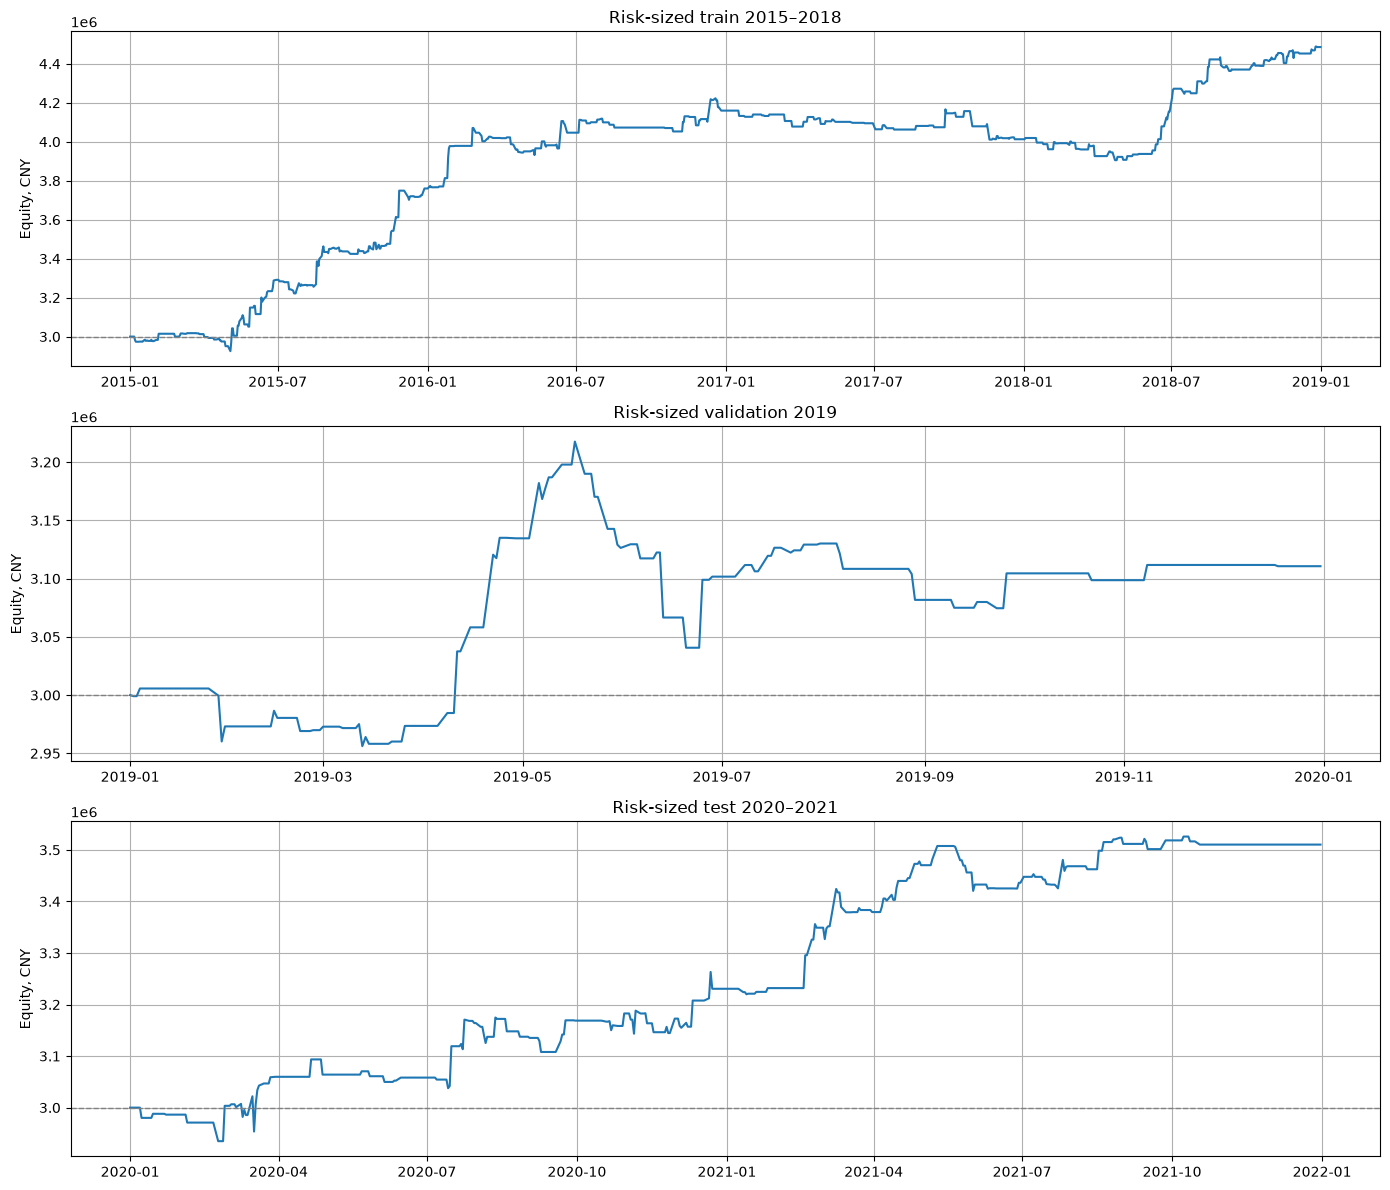

In [61]:
fig, axes = plt.subplots(3, 1, figsize=(14, 12))
titles = {
    "train": "Risk-sized train 2015–2018",
    "validation": "Risk-sized validation 2019",
    "test": "Risk-sized test 2020–2021",
}
for ax, period in zip(axes, ["train", "validation", "test"]):
    daily = risk_sized_daily[period]
    ax.plot(daily.index, daily["equity_cny"])
    ax.axhline(initial_capital, color="gray", linestyle="--", linewidth=1)
    ax.set_title(titles[period])
    ax.set_ylabel("Equity, CNY")
    ax.grid(True)
plt.tight_layout()
plt.show()

## Current conclusion

The notebook now contains a complete first strategy prototype: leakage-safe signal construction, fixed train thresholds, non-overlapping trades, contract-specific fees and slippage, out-of-sample validation/test, margin checks, and volatility-based position sizing. The 0.5% risk budget is an ex-ante sizing rule, not a stop loss or a guaranteed maximum loss. The final table above is the result to use when judging this baseline. Thresholds and sizing parameters must not be retuned on validation or test.

This remains a research baseline rather than deployment-ready evidence: validation is weak and the four instruments are correlated. The next notebook should add an independent signal and later use ML only as a train-fitted filter/combiner.